In [1]:
import pandas as pd
import os

PROJECT_PATH = '/content/drive/MyDrive/Diabetes_Prediction_ML'

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"

columns = [
    'Pregnancies',
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI',
    'DiabetesPedigreeFunction',
    'Age',
    'Outcome'
]

df = pd.read_csv(url, names=columns)

dataset_path = os.path.join(
    PROJECT_PATH,
    'dataset',
    'diabetes.csv'
)

df.to_csv(dataset_path, index=False)

print("Dataset downloaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset downloaded successfully!
Shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [2]:
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Statistical Summary:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000



Missing Values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Duplicate Records:
0


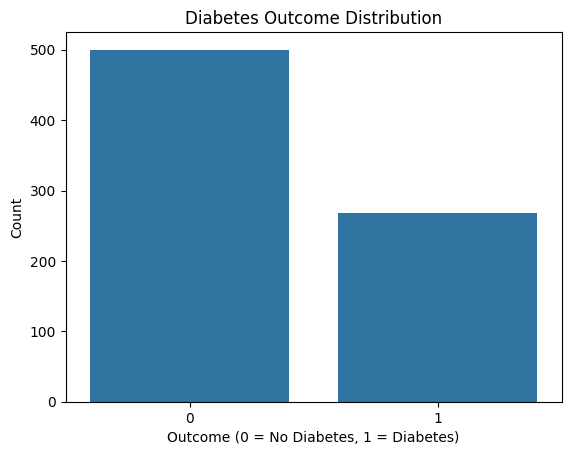

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x='Outcome')

plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("Count")

plt.show()

In [4]:
import os

PROJECT_PATH = '/content/drive/MyDrive/Diabetes_Prediction_ML'

# Create all required folders
folders = [
    'dataset',
    'notebooks',
    'models',
    'outputs'
]

for folder in folders:
    path = os.path.join(PROJECT_PATH, folder)
    os.makedirs(path, exist_ok=True)

print("All folders created successfully!")

# Verify dataset folder
dataset_folder = os.path.join(
    PROJECT_PATH, 'dataset'
)

print("Dataset folder exists:",
      os.path.exists(dataset_folder))

All folders created successfully!
Dataset folder exists: True


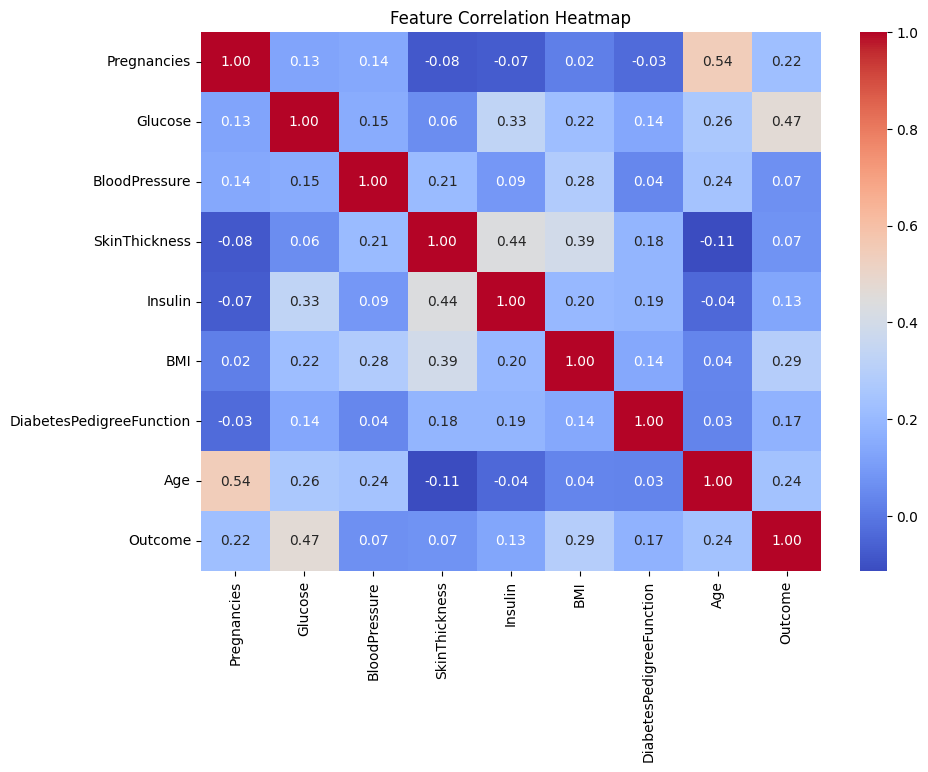

In [5]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Feature Correlation Heatmap")
plt.show()

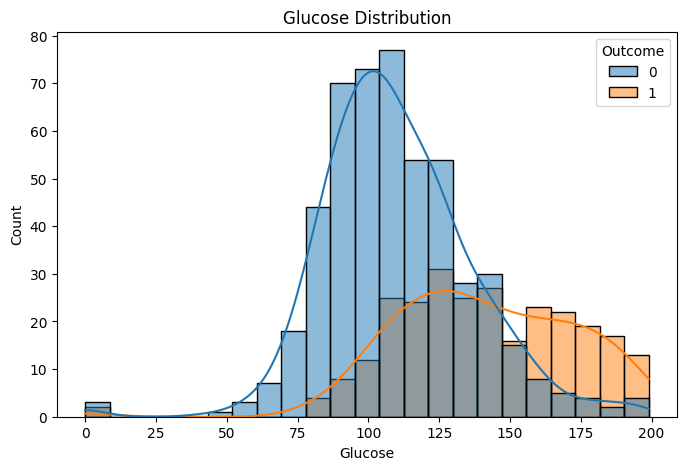

In [6]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='Glucose',
    hue='Outcome',
    kde=True
)

plt.title("Glucose Distribution")
plt.show()

In [7]:
zero_columns = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

for col in zero_columns:
    print(col, ":", (df[col] == 0).sum())

Glucose : 5
BloodPressure : 35
SkinThickness : 227
Insulin : 374
BMI : 11


In [8]:
import numpy as np

df_clean = df.copy()

df_clean[zero_columns] = (
    df_clean[zero_columns].replace(0, np.nan)
)

print(df_clean.isnull().sum())

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [9]:
X = df_clean.drop('Outcome', axis=1)

y = df_clean['Outcome']

print("Input shape:", X.shape)
print("Output shape:", y.shape)

Input shape: (768, 8)
Output shape: (768,)


In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape)
print("Testing records:", X_test.shape)

Training records: (614, 8)
Testing records: (154, 8)


In [11]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

import pandas as pd

In [12]:
models = {

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),

    "SVM": SVC(
        probability=True,
        random_state=42
    )

}

print("Three ML algorithms are ready!")

Three ML algorithms are ready!


In [13]:
trained_models = {}
results = []

for name, algorithm in models.items():

    pipeline = Pipeline([

        ('imputer', SimpleImputer(
            strategy='median'
        )),

        ('scaler', StandardScaler()),

        ('classifier', algorithm)

    ])

    # Train model
    pipeline.fit(X_train, y_train)

    # Predict test data
    predictions = pipeline.predict(X_test)

    # Calculate probabilities
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    # Store trained model
    trained_models[name] = pipeline

    # Evaluate performance
    results.append({

        'Model': name,

        'Accuracy': accuracy_score(
            y_test, predictions
        ),

        'Precision': precision_score(
            y_test, predictions, zero_division=0
        ),

        'Recall': recall_score(
            y_test, predictions, zero_division=0
        ),

        'F1 Score': f1_score(
            y_test, predictions, zero_division=0
        ),

        'ROC-AUC': roc_auc_score(
            y_test, probabilities
        )

    })

print("All models trained successfully!")

All models trained successfully!


In [14]:
results_df = pd.DataFrame(results)

display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.708,0.600,0.500,0.545,0.813
1,Random Forest,0.747,0.660,0.574,0.614,0.816
2,SVM,0.740,0.652,0.556,0.600,0.796


In [15]:
# Select Random Forest model

best_model_name = "Random Forest"

best_model = trained_models[best_model_name]

# Generate predictions
y_pred = best_model.predict(X_test)

print("Selected Model:", best_model_name)
print("Predictions generated successfully!")

Selected Model: Random Forest
Predictions generated successfully!


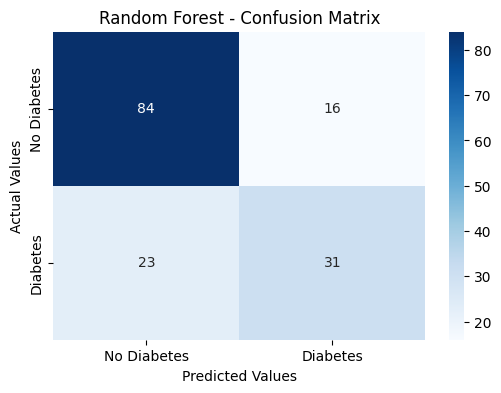

In [16]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Diabetes', 'Diabetes'],
    yticklabels=['No Diabetes', 'Diabetes']
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.show()

In [17]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        target_names=['No Diabetes', 'Diabetes']
    )
)

              precision    recall  f1-score   support

 No Diabetes       0.79      0.84      0.81       100
    Diabetes       0.66      0.57      0.61        54

    accuracy                           0.75       154
   macro avg       0.72      0.71      0.71       154
weighted avg       0.74      0.75      0.74       154



In [18]:
import joblib
import os

PROJECT_PATH = '/content/drive/MyDrive/Diabetes_Prediction_ML'

model_path = os.path.join(
    PROJECT_PATH,
    'models',
    'diabetes_model.pkl'
)

model_bundle = {
    'model': best_model,
    'features': list(X.columns),
    'model_name': best_model_name,
    'threshold': 0.5
}

joblib.dump(model_bundle, model_path)

print("Model saved successfully!")
print("Model location:", model_path)

Model saved successfully!
Model location: /content/drive/MyDrive/Diabetes_Prediction_ML/models/diabetes_model.pkl


In [19]:
loaded_bundle = joblib.load(model_path)

loaded_model = loaded_bundle['model']

print("Model loaded successfully!")
print("Algorithm:", loaded_bundle['model_name'])

Model loaded successfully!
Algorithm: Random Forest


In [20]:
app_code = r'''
import streamlit as st
import pandas as pd
import numpy as np
import joblib
import os

# Load trained model
BASE_DIR = os.path.dirname(os.path.abspath(__file__))
MODEL_PATH = os.path.join(
    BASE_DIR, "models", "diabetes_model.pkl"
)

bundle = joblib.load(MODEL_PATH)
model = bundle["model"]
features = bundle["features"]

# Page configuration
st.set_page_config(
    page_title="Diabetes Prediction",
    page_icon="🩺",
    layout="centered"
)

st.title("🩺 Diabetes Prediction System")
st.write(
    "Enter the health parameters below "
    "to get an ML model prediction."
)

st.info("This application is an educational project, not a medical diagnosis.")

with st.form("prediction_form"):

    st.subheader("Enter Patient Details")

    pregnancies = st.number_input(
        "Pregnancies", min_value=0, max_value=20, value=1
    )

    glucose = st.number_input(
        "Glucose Level", min_value=0.0, value=120.0
    )

    bp = st.number_input(
        "Blood Pressure", min_value=0.0, value=70.0
    )

    skin = st.number_input(
        "Skin Thickness", min_value=0.0, value=20.0
    )

    insulin = st.number_input(
        "Insulin", min_value=0.0, value=80.0
    )

    bmi = st.number_input(
        "BMI", min_value=0.0, value=25.0
    )

    dpf = st.number_input(
        "Diabetes Pedigree Function",
        min_value=0.0, value=0.5
    )

    age = st.number_input(
        "Age", min_value=1, max_value=120, value=30
    )

    submit = st.form_submit_button(
        "Predict Diabetes"
    )

if submit:

    input_data = pd.DataFrame([{
        "Pregnancies": pregnancies,
        "Glucose": glucose,
        "BloodPressure": bp,
        "SkinThickness": skin,
        "Insulin": insulin,
        "BMI": bmi,
        "DiabetesPedigreeFunction": dpf,
        "Age": age
    }])

    # Apply the same zero-as-missing
    # preprocessing used during training.
    for col in [
        "Glucose",
        "BloodPressure",
        "SkinThickness",
        "Insulin",
        "BMI"
    ]:
        if input_data.loc[0, col] == 0:
            input_data.loc[0, col] = np.nan

    input_data = input_data[features]

    prediction = model.predict(input_data)[0]

    probability = model.predict_proba(
        input_data
    )[0][1]

    st.subheader("Prediction Result")

    st.metric(
        "Model-estimated probability",
        f"{probability * 100:.2f}%"
    )

    if prediction == 1:
        st.error(
            "Model Prediction: Diabetes (Positive)"
        )
    else:
        st.success(
            "Model Prediction: No Diabetes (Negative)"
        )

    st.caption(
        "This result is generated by a machine learning "
        "model and must not be used for medical decisions."
    )
'''

app_path = os.path.join(
    PROJECT_PATH, "app.py"
)

with open(app_path, "w") as f:
    f.write(app_code)

print("Streamlit app.py created successfully!")
print("Location:", app_path)

Streamlit app.py created successfully!
Location: /content/drive/MyDrive/Diabetes_Prediction_ML/app.py


In [21]:
requirements = """
streamlit
pandas
numpy
scikit-learn
joblib
"""

requirements_path = os.path.join(
    PROJECT_PATH, "requirements.txt"
)

with open(requirements_path, "w") as f:
    f.write(requirements.strip())

print("requirements.txt created successfully!")

requirements.txt created successfully!


In [22]:
import os

for root, dirs, files in os.walk(PROJECT_PATH):
    level = root.replace(PROJECT_PATH, '').count(os.sep)

    print("  " * level + os.path.basename(root) + "/")

    for file in files:
        print("  " * (level + 1) + file)

Diabetes_Prediction_ML/
  app.py
  requirements.txt
  dataset/
    diabetes.csv
  notebooks/
    Diabetes_Prediction.ipynb
  models/
    diabetes_model.pkl
  outputs/


In [23]:
import joblib
import os

model_path = os.path.join(
    PROJECT_PATH,
    "models",
    "diabetes_model.pkl"
)

bundle = joblib.load(model_path)

print("Model loaded successfully!")

print("Available keys:", bundle.keys())

print("Model algorithm:", bundle["model_name"])

print("Features:", bundle.get("features"))

Model loaded successfully!
Available keys: dict_keys(['model', 'features', 'model_name', 'threshold'])
Model algorithm: Random Forest
Features: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']


In [24]:
import pandas as pd

# Sample patient details
sample_patient = pd.DataFrame([{
    "Pregnancies": 2,
    "Glucose": 120,
    "BloodPressure": 70,
    "SkinThickness": 25,
    "Insulin": 80,
    "BMI": 28.5,
    "DiabetesPedigreeFunction": 0.5,
    "Age": 35
}])

# Arrange features in correct order
sample_patient = sample_patient[bundle["features"]]

# Predict
prediction = bundle["model"].predict(sample_patient)

probability = bundle["model"].predict_proba(
    sample_patient
)[0][1]

threshold = bundle["threshold"]

print("Prediction:", prediction[0])
print("Probability:", round(probability * 100, 2), "%")
print("Threshold:", threshold)

if probability >= threshold:
    print("Result: Diabetes Positive")
else:
    print("Result: Diabetes Negative")

Prediction: 0
Probability: 33.0 %
Threshold: 0.5
Result: Diabetes Negative


In [25]:
!pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 42.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 94.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [26]:
import os

app_path = os.path.join(PROJECT_PATH, "app.py")

print("App exists:", os.path.exists(app_path))
print("App location:", app_path)

App exists: True
App location: /content/drive/MyDrive/Diabetes_Prediction_ML/app.py


In [27]:
%cd /content/drive/MyDrive/Diabetes_Prediction_ML

!streamlit run app.py --server.port 8501 &>/content/streamlit.log &

/content/drive/MyDrive/Diabetes_Prediction_ML


In [28]:
!npm install -g localtunnel

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧
added 22 packages in 3s
⠧
⠧3 packages are looking for funding
⠧  run `npm fund` for details
⠧

In [ ]:
!lt --port 8501

your url is: https://cuddly-chicken-lick.loca.lt
/tools/node/lib/node_modules/localtunnel/bin/lt.js:81
    throw err;
    ^

Error: connection refused: localtunnel.me:30895 (check your firewall settings)
    at Socket.<anonymous> (/tools/node/lib/node_modules/localtunnel/lib/TunnelCluster.js:52:11)
    at Socket.emit (node:events:519:28)
    at emitErrorNT (node:internal/streams/destroy:170:8)
    at emitErrorCloseNT (node:internal/streams/destroy:129:3)
    at process.processTicksAndRejections (node:internal/process/task_queues:89:21)

Node.js v22.23.4


In [ ]:
!cat /content/streamlit.log



2026-11-22 16:14:56.982 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://34.34.126.126:8501



In [ ]:
!streamlit run /content/drive/MyDrive/Diabetes_Prediction_ML/app.py --server.port 8501 > /content/streamlit.log 2>&1 &

In [ ]:
!sleep 5
!cat /content/streamlit.log



2026-11-23 03:28:46.629 Port 8501 is not available


In [ ]:
import subprocess
import time
import requests
import os

app_path = "/content/drive/MyDrive/Diabetes_Prediction_ML/app.py"

with open("/content/streamlit.log", "w") as log:
    process = subprocess.Popen(
        ["streamlit", "run", app_path,
         "--server.port", "8501",
         "--server.address", "0.0.0.0"],
        stdout=log,
        stderr=subprocess.STDOUT
    )

time.sleep(10)

try:
    response = requests.get("http://127.0.0.1:8501")
    print("Streamlit is running!")
    print("Status:", response.status_code)
except Exception as e:
    print("Streamlit error:", e)

Streamlit is running!
Status: 200


In [ ]:
!cat /content/streamlit.log



2026-11-23 03:28:51.773 Port 8501 is not available


In [ ]:
!curl -I http://127.0.0.1:8501

HTTP/1.1 200 OK
date: Mon, 23 Nov 2026 03:28:59 GMT
server: uvicorn
content-type: text/html; charset=utf-8
accept-ranges: bytes
content-length: 7863
last-modified: Sun, 22 Nov 2026 16:14:48 GMT
etag: "71b17f8d2a866cc1444de1564718c05f"
cache-control: no-cache



In [ ]:
!lt --port 8501 --print-requests

your url is: https://metal-parrots-try.loca.lt
